# Evaluación de modelos de detección de anomalías en contratos electrónicos de SECOP II

Este notebook evalúa diferentes métodos de detección de anomalías sobre los contratos electrónicos de SECOP II correspondientes a septiembre de 2026. Se comparan Isolation Forest, Local Outlier Factor (LOF) y un método estadístico basado en percentiles, con el propósito de identificar comportamientos atípicos y evaluar la estabilidad de los resultados. Las puntuaciones obtenidas no representan por sí mismas irregularidades en la contratación.


## 1. Configuración

Se define el periodo de análisis, la semilla para reproducir los experimentos y las rutas donde se almacenarán los resultados. Los datos de PostgreSQL se consultan sin modificarlos.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

NB_DIR = Path("/home/jovyan/work/spark-apps/notebooks")
if not NB_DIR.exists():
    NB_DIR = Path.cwd().resolve()
    if NB_DIR.name == "ml":
        NB_DIR = NB_DIR.parent
SRC = NB_DIR.parent / "src"
sys.path.insert(0, str(SRC))

from transformation.spark_sesion import _asegurar_pyspark, crear_spark

_asegurar_pyspark()
from ml.experimentos import correr_fase

PERIODO = "2026-09"
ESCRIBIR_PG = False
SEMILLA = 42
SALIDAS = NB_DIR / "salidas" / "ml" / PERIODO / "contratos"
FIGURAS = SALIDAS / "figuras"
SALIDAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

print("Periodo:", PERIODO)
print("ESCRIBIR_PG:", ESCRIBIR_PG)
print("Semilla:", SEMILLA)
print("Salidas:", SALIDAS)
print("PGUSER definido:", bool(os.environ.get("PGUSER")))
assert not ESCRIBIR_PG, "Esta fase no escribe en PostgreSQL."


Periodo: 2026-09
ESCRIBIR_PG: False
Semilla: 42
Salidas: /home/jovyan/work/spark-apps/notebooks/salidas/ml/2026-09/contratos
PGUSER definido: True


## 2. Ejecución de los experimentos

Se consultan los contratos almacenados en PostgreSQL y se ejecutan los experimentos de detección de anomalías. Los modelos Isolation Forest y LOF se evalúan sobre el mismo conjunto de datos, utilizando un método estadístico como referencia para comparar sus resultados.

In [2]:
import json

FORZAR = True
hay_salidas = (SALIDAS / "resumen.json").exists()
if FORZAR or not hay_salidas:
    spark = crear_spark("nb09-anomalias-contratos")
    print("Spark:", spark.version, spark.sparkContext.master)
    res = correr_fase(spark, PERIODO, SALIDAS, semilla=SEMILLA)
    spark.stop()
else:
    print("Reutiliza", SALIDAS / "resumen.json")
    resumen = json.loads((SALIDAS / "resumen.json").read_text(encoding="utf-8"))
    res = {
        "ganador": resumen["ganador"],
        "nota_ganador": resumen["nota_ganador"],
        "plazo": resumen["plazo"],
    }
print("Ganador C4/inspección:", res["ganador"])
print(res["nota_ganador"])


Spark: 3.5.0 local[*]
C0: log1p_valor
C0 tiempos {'if_s': 1.803, 'lof_s': 0.334}
C1: ['log1p_valor', 'log_valor_vs_modalidad'] + dummies
C1 tiempos {'if_s': 1.631, 'lof_s': 0.811}
C2: + dias_ejecucion
C2 tiempos {'if_s': 1.554, 'lof_s': 1.125}
C3: ['log1p_valor', 'log_valor_vs_modalidad', 'dias_ejecucion', 'log1p_n_entidad']
C3 tiempos {'if_s': 1.59, 'lof_s': 1.246}
ganador C3 C3 mueve el ranking IF respecto de C1 (Jaccard top 5 %=0.586). Se usa C3 en C4 e inspección.
estabilidad IF semillas
estabilidad submuestra
sensibilidad LOF 20 vs 50
permutacion IF
Ganador C4/inspección: C3
C3 mueve el ranking IF respecto de C1 (Jaccard top 5 %=0.586). Se usa C3 en C4 e inspección.


## 3. Selección de los contratos

Se verifica el conjunto de contratos utilizado para entrenar los modelos. Se consideran 82.457 contratos con valores aptos para el análisis, mientras que los 506 registros con valor cero y el registro con valor extremo se revisan por separado.

In [3]:
universo = pd.read_csv(SALIDAS / "universo.csv")
decisiones = pd.read_csv(SALIDAS / "decisiones.csv")
display(universo)
display(decisiones)
assert int(universo.loc[universo["conjunto"] == "valor_apto_modelo", "n"].iloc[0]) == 82457
assert int(universo.loc[universo["conjunto"] == "valor_cero", "n"].iloc[0]) == 506
assert int(universo.loc[universo["conjunto"] == "valor_extremo", "n"].iloc[0]) == 1


,conjunto,n,uso
0,tfm.contrato,82964,descriptivo
1,valor_apto_modelo,82457,entrenamiento y ranking
2,valor_cero,506,"ficha C5, fuera del ajuste"
3,valor_extremo,1,"ficha C5, fuera del ajuste"
4,es_bogota y apto,11167,recorte C4


,decision,detalle
0,universo,82457 aptos; ceros y extremo fuera del ajuste
1,plazo_confiable,True
2,pct_plazo_valido,94.82
3,C2,ejecutado
4,numericas_c1,log1p_valor + log_valor_vs_modalidad
5,ganador,C3
6,nota_ganador,C3 mueve el ranking IF respecto de C1 (Jaccard...
7,semilla,42
8,escribir_pg,false


## 4. Plazo y redundancia

Se revisa la disponibilidad y calidad de las fechas de ejecución para determinar si el plazo puede utilizarse como variable de análisis. También se evalúa la relación entre las variables para evitar incorporar información redundante.

In [4]:
plazo = pd.read_csv(SALIDAS / "informe_plazo.csv")
red = pd.read_csv(SALIDAS / "redundancia.csv")
display(plazo)
display(red.round(3))
print("Plazo confiable:", bool(res["plazo"]["plazo_confiable"]))


,n,fecha_inicio_nula,fecha_fin_nula,dias_nulos,dias_le_0,dias_gt_10a,dias_validos,pct_validos,mediana_validos,p95_validos,firma_inicio_mediana,plazo_confiable
0,82457,4089,1,4089,178,4,78186,94.82,90.0,121.0,0.0,True


,variable,log1p_valor,log_valor_vs_modalidad,dias_ejecucion,log1p_n_entidad
0,log1p_valor,1.000,0.895,0.384,-0.118
1,log_valor_vs_modalidad,0.895,1.000,0.432,-0.017
2,dias_ejecucion,0.384,0.432,1.000,0.057
3,log1p_n_entidad,-0.118,-0.017,0.057,1.000


Plazo confiable: True


## 5. Comparación de experimentos

Se comparan diferentes combinaciones de variables para determinar cuáles permiten identificar mejor los comportamientos atípicos. Se evalúan los resultados de Isolation Forest y LOF, así como su relación con el método estadístico de referencia, utilizando métricas de concordancia y clasificación de los contratos.

- **C0:** solo `log1p(valor)`.
- **C1:** residuo vs mediana de la modalidad + dummies agrupadas.
- **C2:** C1 + plazo, si es confiable.
- **C3:** + tamaño de la entidad en el mes.
- **C4:** recorte Bogotá, misma matriz ganadora, se reajusta.


In [5]:
metricas = pd.read_csv(SALIDAS / "metricas_experimentos.csv")
display(metricas)
for eid in metricas["experimento"]:
    print("\n===", eid, "===")
    display(pd.read_csv(SALIDAS / f"{eid.lower()}_solape.csv"))
    display(pd.read_csv(SALIDAS / f"{eid.lower()}_spearman.csv"))


,experimento,matriz,n_vars,if_s,lof_s,jaccard_if_lof_1,jaccard_base_if_1,jaccard_base_lof_1,n_if_lof_1,jaccard_if_lof_5,jaccard_base_if_5,jaccard_base_lof_5,n_if_lof_5,spearman_base_if,spearman_base_lof,spearman_if_lof
0,C0,log1p_valor,1,1.803,0.334,0.0086,0.7152,0.0,14,0.0250,0.5497,0.0102,201,0.2533,0.0416,0.0856
1,C1,log1p_valor + log_valor_vs_modalidad + mod_Con...,9,1.631,0.811,0.0073,0.3502,0.0,12,0.0021,0.4341,0.0004,17,0.2131,0.0384,0.0965
2,C2,log1p_valor + log_valor_vs_modalidad + dias_ej...,11,1.554,1.125,0.0000,0.2911,0.0,0,0.0013,0.4050,0.0000,11,0.1605,0.0087,0.1043
3,C3,log1p_valor + log_valor_vs_modalidad + dias_ej...,12,1.590,1.246,0.0000,0.2519,0.0,0,0.0024,0.3732,0.0000,20,0.2120,-0.0156,0.0356
4,C4,log1p_valor + log_valor_vs_modalidad + dias_ej...,12,0.672,0.104,0.0000,0.1789,0.0,0,0.0118,0.3083,0.0054,13,0.0300,-0.0293,0.1363



=== C0 ===


,frac,k,n_p99mod,jaccard_base_if,n_base_if,coinc_base_if,jaccard_base_lof,n_base_lof,coinc_base_lof,jaccard_if_lof,...,coinc_base_p99,jaccard_base_p99,n_if_p99,coinc_if_p99,jaccard_if_p99,n_lof_p99,coinc_lof_p99,jaccard_lof_p99,jaccard_if_lof_p99,n_if_lof_p99
0,0.01,825,828,0.7152,688,0.8339,0.0000,0,0.0000,0.0086,...,0.3891,0.2410,278,0.3370,0.2022,5,0.0061,0.0030,0.0000,0
1,0.05,4123,828,0.5497,2925,0.7094,0.0102,83,0.0201,0.0250,...,0.2008,0.2008,741,0.1797,0.1760,9,0.0022,0.0018,0.0088,9


,par,spearman,p
0,score_base vs score_if,0.2533,0.000000e+00
1,score_base vs score_lof,0.0416,6.791491e-33
2,score_if vs score_lof,0.0856,6.554161e-134



=== C1 ===


,frac,k,n_p99mod,jaccard_base_if,n_base_if,coinc_base_if,jaccard_base_lof,n_base_lof,coinc_base_lof,jaccard_if_lof,...,coinc_base_p99,jaccard_base_p99,n_if_p99,coinc_if_p99,jaccard_if_p99,n_lof_p99,coinc_lof_p99,jaccard_lof_p99,jaccard_if_lof_p99,n_if_lof_p99
0,0.01,825,828,0.3502,428,0.5188,0.0000,0,0.0000,0.0073,...,0.3891,0.2410,79,0.0958,0.0502,0,0.0,0.0,0.0,0
1,0.05,4123,828,0.4341,2496,0.6054,0.0004,3,0.0007,0.0021,...,0.2008,0.2008,368,0.0893,0.0803,0,0.0,0.0,0.0,0


... (6 outputs left out)

,par,spearman,p
0,score_base vs score_if,0.2120,0.000000e+00
1,score_base vs score_lof,-0.0156,7.118357e-06
2,score_if vs score_lof,0.0356,1.343303e-24



=== C4 ===


,frac,k,n_p99mod,jaccard_base_if,n_base_if,coinc_base_if,jaccard_base_lof,n_base_lof,coinc_base_lof,jaccard_if_lof,...,coinc_base_p99,jaccard_base_p99,n_if_p99,coinc_if_p99,jaccard_if_p99,n_lof_p99,coinc_lof_p99,jaccard_lof_p99,jaccard_if_lof_p99,n_if_lof_p99
0,0.01,112,115,0.1789,34,0.3036,0.0000,0,0.0000,0.0000,...,0.3750,0.2270,12,0.1071,0.0558,0,0.0000,0.0000,0.0000,0
1,0.05,558,115,0.3083,263,0.4713,0.0054,6,0.0108,0.0118,...,0.1953,0.1933,40,0.0717,0.0632,1,0.0018,0.0015,0.0079,1


,par,spearman,p
0,score_base vs score_if,0.0300,1.501742e-03
1,score_base vs score_lof,-0.0293,1.976195e-03
2,score_if vs score_lof,0.1363,1.814712e-47


## 6. Estabilidad y sensibilidad de los modelos

Se verifica si los resultados se mantienen al cambiar la semilla, utilizar diferentes muestras de contratos y modificar el número de vecinos de LOF. También se analiza la importancia de las variables para comprender su influencia en las puntuaciones obtenidas.


In [6]:
est_sem = pd.read_csv(SALIDAS / "estabilidad_semillas.csv")
est_sub = pd.read_csv(SALIDAS / "estabilidad_submuestra.csv")
sens = pd.read_csv(SALIDAS / "sensibilidad_vecinos.csv")
imp = pd.read_csv(SALIDAS / "importancia_permutacion.csv")
print("Jaccard medio top 5 % entre semillas IF:", round(est_sem["jaccard_top5"].mean(), 4))
print("Spearman medio entre semillas IF:", round(est_sem["spearman"].mean(), 4))
print("Jaccard medio submuestra 80 %:", round(est_sub["jaccard_top5"].mean(), 4))
display(est_sem)
display(est_sub)
display(sens)
display(imp)


Jaccard medio top 5 % entre semillas IF: 0.7995
Spearman medio entre semillas IF: 0.9894
Jaccard medio submuestra 80 %: 0.54


,semilla_a,semilla_b,spearman,jaccard_top5
0,42,7,0.9903,0.8044
1,42,13,0.9901,0.7946
2,42,99,0.9807,0.8095
3,42,2026,0.9915,0.8398
4,7,13,0.9920,0.8163
5,7,99,0.9893,0.8004
6,7,2026,0.9923,0.7733
7,13,99,0.9868,0.7703
8,13,2026,0.9928,0.8020
9,99,2026,0.9881,0.7841


,rep_a,rep_b,jaccard_top5
0,0,1,0.5875
1,0,2,0.5455
2,0,3,0.5404
3,0,4,0.5286
4,1,2,0.5671
5,1,3,0.5742
6,1,4,0.5094
7,2,3,0.5219
8,2,4,0.5347
9,3,4,0.4910


,vecinos_a,vecinos_b,jaccard_top5,spearman,tiempo_a_s,tiempo_b_s
0,20,50,0.178,0.5036,1.211,1.853


,variable,spearman_medio_barajada,caida
0,log1p_n_entidad,0.8403,0.1597
1,dias_ejecucion,0.8434,0.1566
2,mod_Contratación directa,0.8534,0.1466
3,log1p_valor,0.8852,0.1148
4,plazo_invalido,0.8911,0.1089
5,log_valor_vs_modalidad,0.8937,0.1063
6,mod_Contratación régimen especial,0.9196,0.0804
7,mod_Mínima cuantía,0.9609,0.0391
8,mod_otras,0.9876,0.0124
9,mod_Selección Abreviada de Menor Cuantía,0.9896,0.0104


## 7. Revisión de contratos identificados

Se examina una muestra de al menos 20 contratos con puntuaciones atípicas elevadas, seleccionados mediante Isolation Forest y LOF. Esta revisión permite describir sus características y formular posibles explicaciones, sin considerar automáticamente estos casos como irregularidades.

In [7]:
casos = pd.read_csv(SALIDAS / "inspeccion_20.csv")
print("Filas:", len(casos))
assert len(casos) >= 20
display(casos)


Filas: 24


,id_contrato,socrata_id,nombre_entidad,departamento,ciudad,proveedor_adjudicado,modalidad_de_contratacion,valor_del_contrato,log1p_valor,dias_ejecucion,...,n_entidad,es_bogota,estado_homologacion,score_base,score_if,score_lof,flag_p99_mod,rank_base,rank_if,rank_lof
0,CO1.PCCNTR.9832569,row-bxxw_95pz_ivsc,AAPSA ESP**,Cauca,Popayán,CONSORCIO PTAP PALACE 2026,Licitación pública Obra Publica,8.254363e+10,25.136593,NaN,...,2,False,homologado,25.136593,0.142906,1.474360e+00,1,9,1,9087
1,CO1.PCCNTR.9906125,row-cm3c.q9c2.hnus,ALCALDÍA DEL DISTRITO TURÍSTICO Y CULTURAL DE ...,Bolívar,Cartagena,CONSORCIO DISTRITO CTC,Licitación pública Obra Publica,8.783142e+10,25.198685,455.0,...,2282,False,homologado,25.198685,0.142361,1.162698e+00,1,8,2,18468
2,CO1.PCCNTR.9673418,row-agrd.wtks.6kd3,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN RAFAEL.*,Antioquia,Yolombó,CONSORCIO TORRE CLINICA YOLOMBÓ 2026,Contratación régimen especial (con ofertas),7.900877e+10,25.092825,1092.0,...,2,False,homologado,25.092825,0.133912,1.567377e+00,1,10,3,8182
3,CO1.PCCNTR.9854026,row-q3eh-jfkb~8hsm,ALCALDÍA DEL DISTRITO TURÍSTICO Y CULTURAL DE ...,Bolívar,Cartagena,CONSORCIO DISTRITO CREATIVO IC,Concurso de méritos abierto,7.551551e+09,22.745019,456.0,...,2282,False,homologado,22.745019,0.131616,9.992764e-01,0,120,4,66333
4,CO1.PCCNTR.9901880,row-m8yb-t47b~7p2r,CORPORACIÓN AUTÓNOMA REGIONAL DEL ATLÁNTICO,Atlántico,Barranquilla,UT ATLANTICO RENACE,Licitación pública,2.704000e+10,24.020583,670.0,...,6,False,homologado,24.020583,0.129337,1.546722e+00,1,25,5,8325
5,CO1.PCCNTR.9972314,row-dhci~7cib.4cc8,ALCALDÍA LOCAL DE BARRIOS UNIDOS,Distrito Capital de Bogotá,Bogotá,"AGENCIA DISTRITAL PARA LA EDUCACIÓN SUPERIOR, ...",Contratación Directa (con ofertas),3.889924e+09,22.081655,2838.0,...,6,True,homologado,22.081655,0.128099,1.318011e+00,0,244,6,11857
6,CO1.PCCNTR.9813964,row-zyzm~cr4n.c9xn,HOSPITAL DEL SARARE ESE,Arauca,No Definido,CONSORCIO SARAVENA 2026.,Contratación régimen especial (con ofertas),2.685615e+10,24.013761,504.0,...,2,False,sin_municipio,24.013761,0.127340,1.131469e+00,1,26,7,20959
7,CO1.PCCNTR.9909043,row-wgfj_t8xj.cujr,MUNICIPIO DE BUCARAMANGA,Santander,Bucaramanga,UT ESPACIO PUBLICO BGA 2026,Licitación pública Obra Publica,1.084652e+10,23.107110,NaN,...,1043,False,homologado,23.107110,0.126718,1.079615e+00,0,73,8,27416
8,CO1.PCCNTR.9722209,row-ny4z-pwdu_2yxv,DEPARTAMENTO DE CORDOBA,Córdoba,Montería,CONSORCIO ESTRATEGIA VIAL,Licitación pública Obra Publica,2.313916e+11,26.167377,NaN,...,149,False,homologado,26.167377,0.126669,1.503359e+00,1,3,9,8735
9,CO1.PCCNTR.9924210,row-yq8q-84gn-b5p5,MUNICIPIO DE FUNZA - ALCALDÍA DE FUNZA,Cundinamarca,Funza,"EMPRESA DE ACUEDUCTO, ALCANTARILLADO Y ASEO DE...",Contratación Directa (con ofertas),1.039650e+10,23.064735,364.0,...,164,False,homologado,23.064735,0.126645,1.031800e+00,0,79,10,38433


## 8. Análisis de Bogotá y valores especiales

Se ejecuta una evaluación específica para los contratos de Bogotá y se comparan sus resultados con los obtenidos a nivel nacional. Los contratos con valores en cero o extremos se analizan por separado como situaciones de calidad de datos, sin clasificarlos automáticamente como anomalías.

In [8]:
display(pd.read_csv(SALIDAS / "c4_vs_nacional.csv"))
display(pd.read_csv(SALIDAS / "c5_ceros.csv"))
display(pd.read_csv(SALIDAS / "c5_extremo.csv"))
display(pd.read_csv(SALIDAS / "c5_ceros_modalidad.csv").head(10))
display(pd.read_csv(SALIDAS / "c5_ceros_entidad.csv"))


,n_bogota_aptos,n_top5_nacional_en_bogota,n_top5_c4,jaccard_if_nacional_vs_c4,n_comun
0,11167,558,558,0.7169,466


,campo,valor
0,n,506
1,modalidad_mas_frecuente,Contratación directa
2,n_entidades,187
3,n_bogota,105
4,estado:En ejecución,421
5,estado:Aprobado,57
6,estado:Modificado,15
7,estado:terminado,12
8,estado:Suspendido,1


,id_contrato,socrata_id,nombre_entidad,ciudad,proveedor_adjudicado,modalidad_de_contratacion,valor_del_contrato,estado_contrato,fecha_de_firma
0,CO1.PCCNTR.9953923,row-emg4_f955_wmez,INSTITUTO DE DEPORTES Y RECREACION DE MEDELLIN,Medellín,EMPRESA DE DESARROLLO URBANO DE MEDELLIN,Contratación directa,1.159398e+12,En ejecución,2026-09-16 15:54:58.077


,modalidad_de_contratacion,n
0,Contratación directa,455
1,Contratación régimen especial,33
2,Contratación régimen especial (con ofertas),11
3,Concurso de méritos abierto,4
4,Licitación pública,1
5,Contratación Directa (con ofertas),1
6,Selección Abreviada de Menor Cuantía,1


,nombre_entidad,n
0,BIBLIOTECA PUBLICA PILOTO DE MEDELLIN PARA AME...,71
1,IDARTES,36
2,MUNICIPIO DE ENVIGADO*,28
3,ALCALDIA DE EL PEÑOL,22
4,ALCALDIA MUNICIPIO DE LA VEGA CUNDINAMARCA,15
5,ICBF REGIONAL CAQUETA,15
6,ICBF REGIONAL NARIÑO,10
7,MUNICIPIO DE PUERTO GAITAN,10
8,ALCALDIA MUNICIPIO DE CIRCASIA QUINDIO,8
9,UNIVERSIDAD MILITAR NUEVA GRANADA**,8


## 9. Visualización de los resultados

Se presentan gráficos para comparar la distribución de los valores de los contratos, las puntuaciones de los modelos, la coincidencia entre sus resultados y la importancia de las variables utilizadas.

hist_log10_valor.png ok


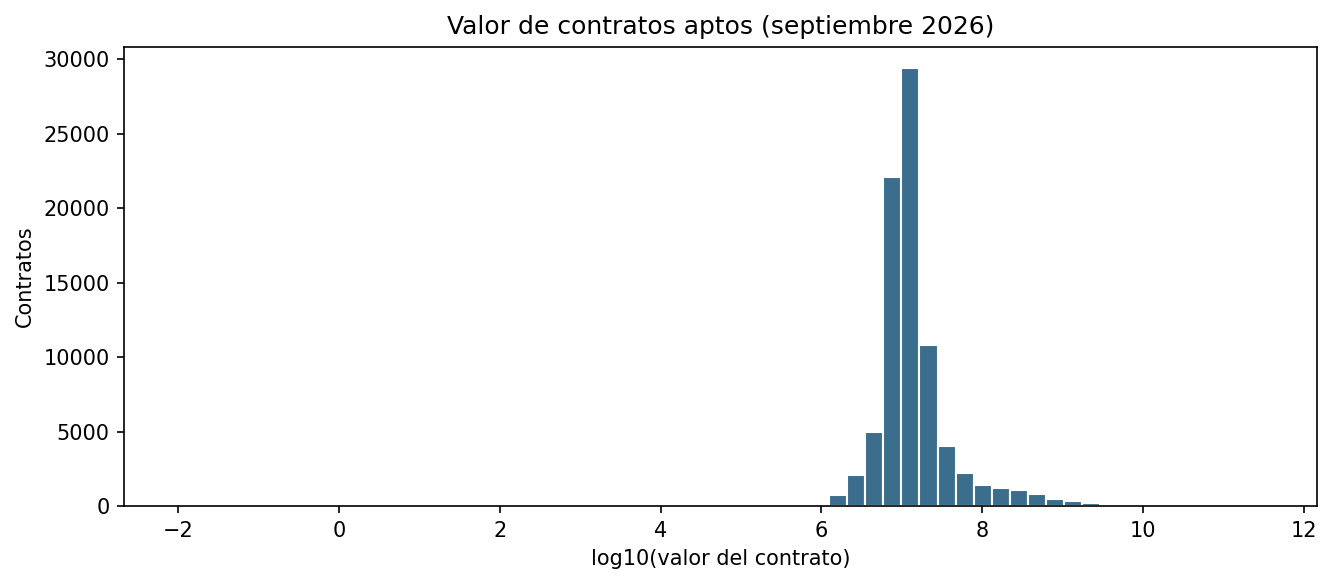

box_log10_modalidad.png ok


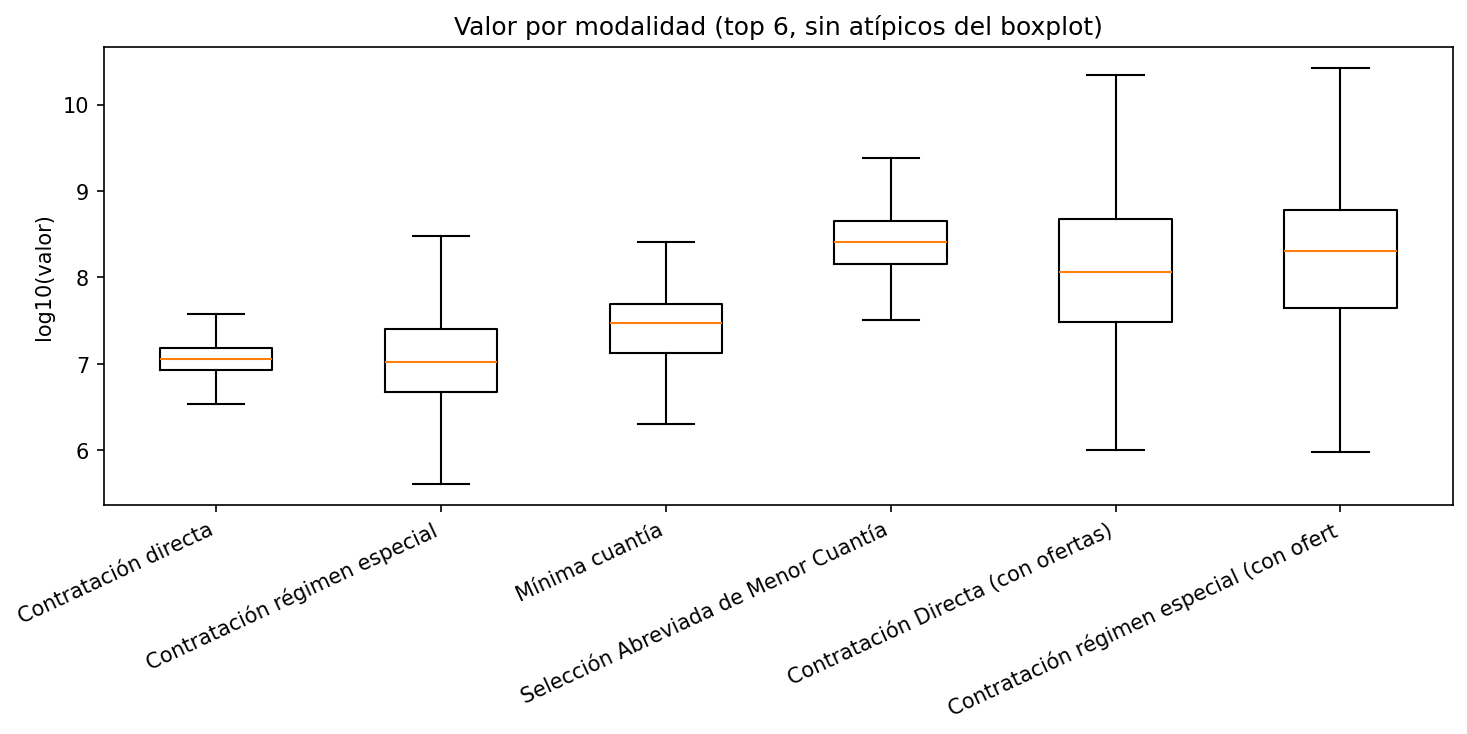

scatter_ranks_if_lof.png ok


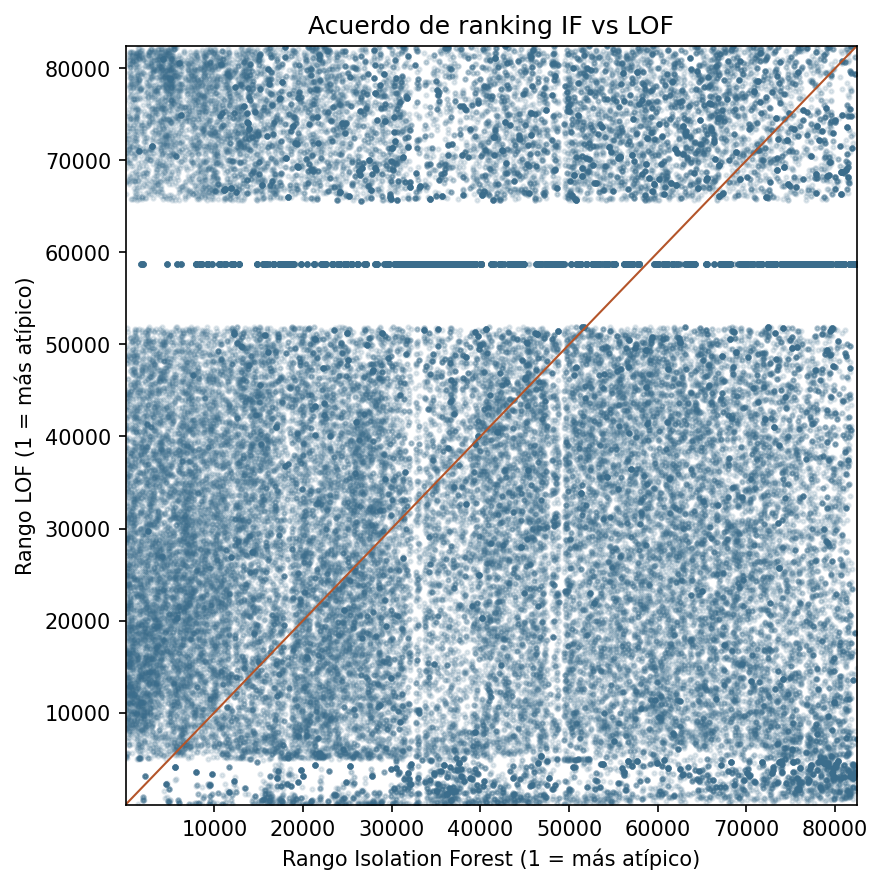

solape_top5.png ok


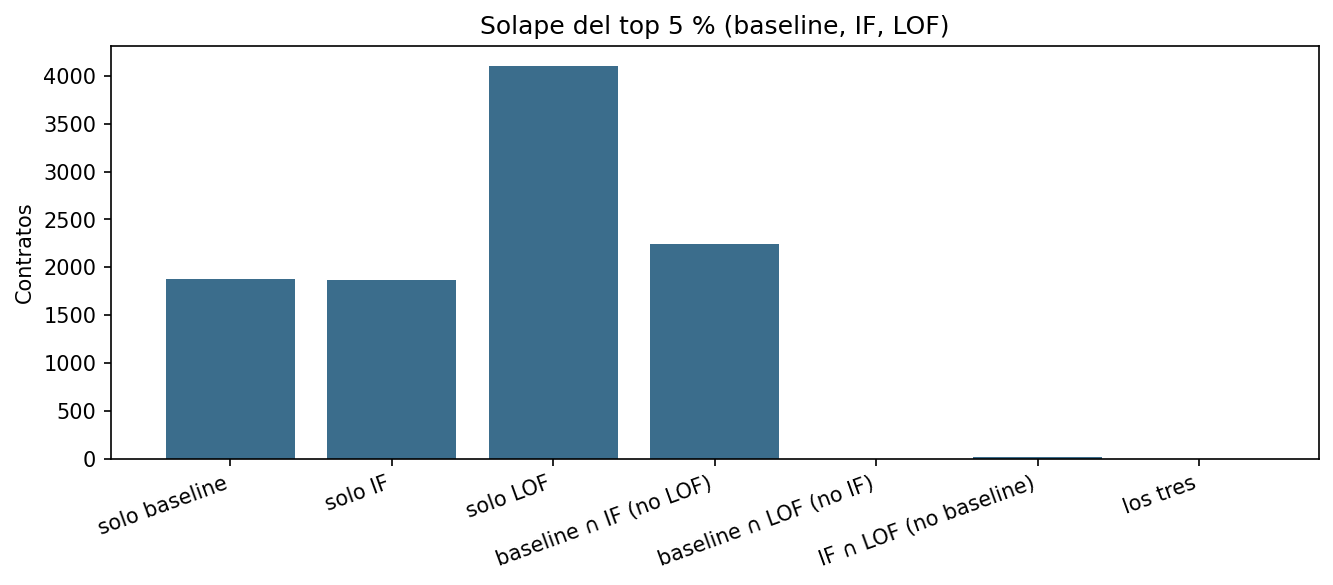

composicion_modalidad.png ok


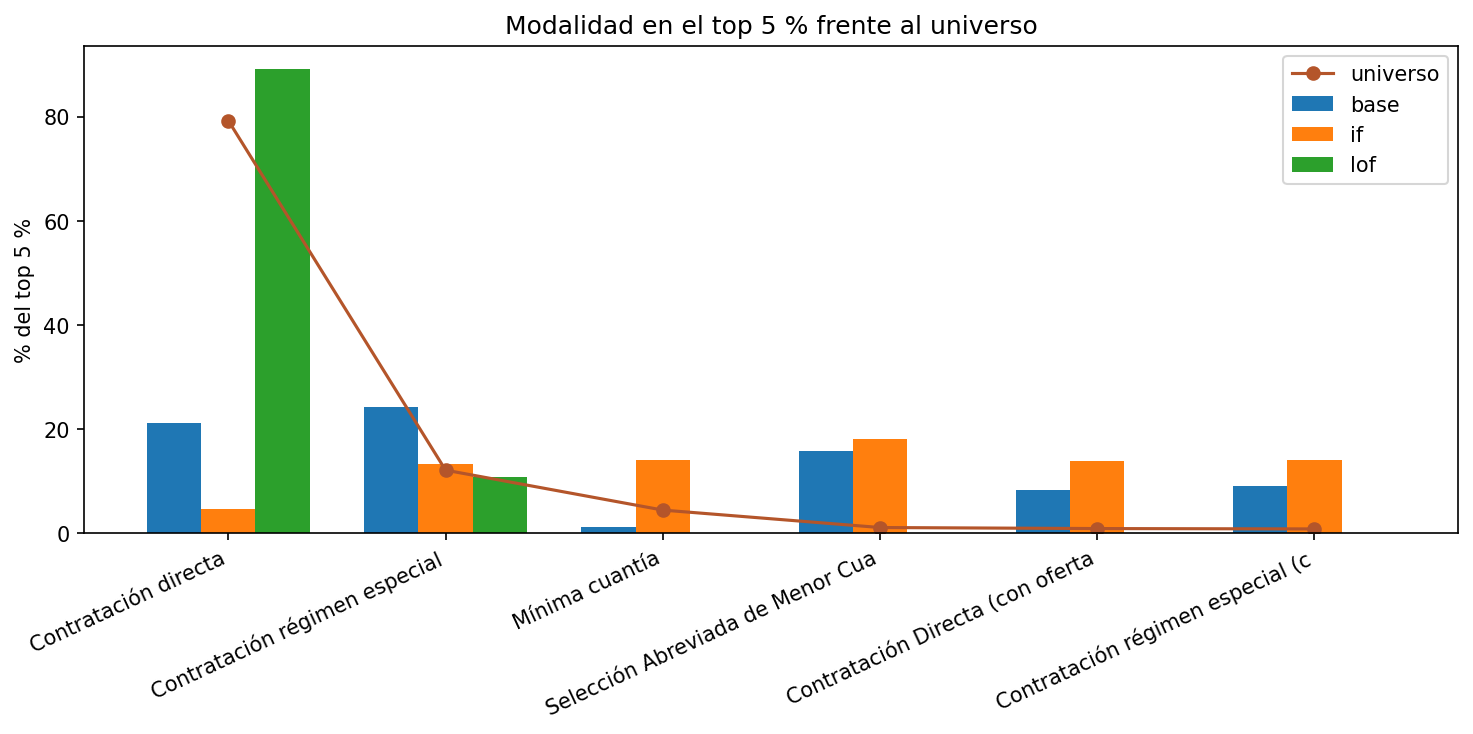

permutacion_if.png ok


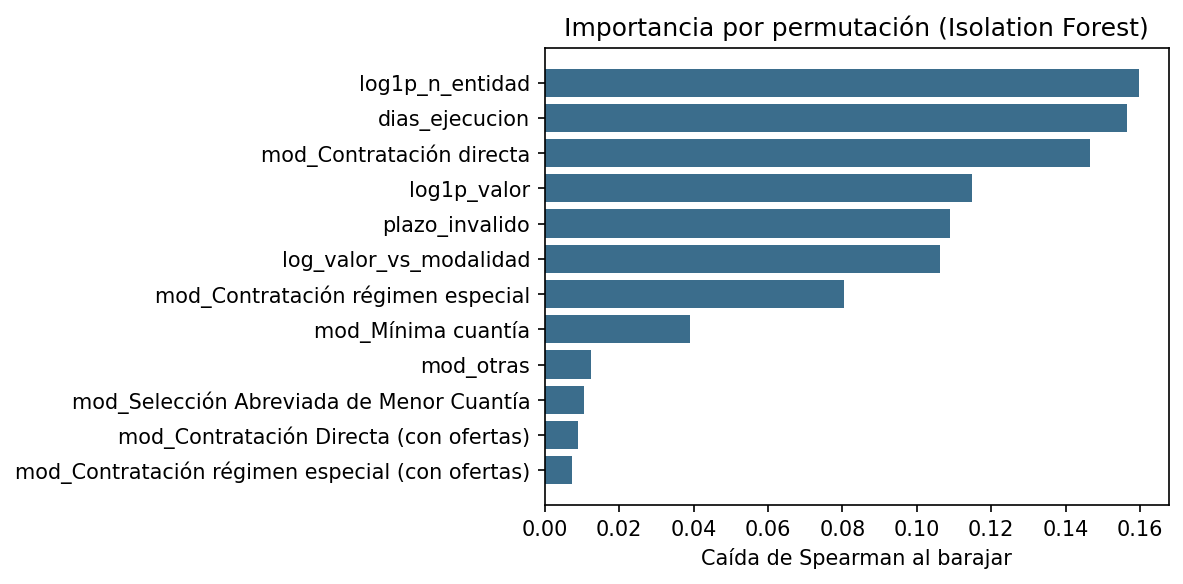

In [9]:
for nombre in [
    "hist_log10_valor.png",
    "box_log10_modalidad.png",
    "scatter_ranks_if_lof.png",
    "solape_top5.png",
    "composicion_modalidad.png",
    "permutacion_if.png",
]:
    ruta = FIGURAS / nombre
    print(ruta.name, "ok" if ruta.exists() else "FALTA")
    if ruta.exists():
        display(Image(filename=str(ruta)))
